In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [8]:
BASE = Path(r"D:/BlueRose/iffco_discount_model/results")

segments = ["high", "medium", "low"]

raw = {}
stab = {}

for seg in segments:
    raw_file  = BASE /  f"prediction_vs_actual_{seg}.csv"
    stab_file = BASE / "stabilized" / f"prediction_vs_actual_{seg}.stabilized.csv"
    
    raw[seg]  = pd.read_csv(raw_file, parse_dates=["PLOT_DATE"])
    stab[seg] = pd.read_csv(stab_file, parse_dates=["PLOT_DATE"])

print("Loaded:", list(raw.keys()))


Loaded: ['high', 'medium', 'low']


In [9]:
SEG = "high"   # high / medium / low

df = raw[SEG].merge(
    stab[SEG][[
        "CUSTOMER",
        "PRODUCT_GROUP",
        "PLOT_DATE",
        "STABILIZED_FINAL"
    ]],
    on=["CUSTOMER","PRODUCT_GROUP","PLOT_DATE"],
    how="left"
)

df.head()


,CUSTOMER,PRODUCT_GROUP,PLOT_DATE,SALES,PREDICTION,STABILIZED_FINAL
0,\tENOC SITE 1635 - AL KHAWANEEJ -F,Chocolate,2024-03-01,2.26,21.973003,4.4750
1,\tENOC SITE 1635 - AL KHAWANEEJ -F,Chocolate,2024-04-01,2.26,21.871203,5.0625
2,\tENOC SITE 1635 - AL KHAWANEEJ -F,Chocolate,2024-06-01,1.60,21.871203,5.6500
3,\tENOC SITE 1635 - AL KHAWANEEJ -F,Chocolate,2024-07-01,1.13,21.871203,5.6500
4,\tENOC SITE 1635 - AL KHAWANEEJ -F,Chocolate,2024-08-01,2.26,21.973003,4.0000


In [11]:
customer = "2192 LULU HYPERMARKET SP LLC BRANCH-F"
product  = "Ice creams"

view = df[
    (df["CUSTOMER"] == customer) &
    (df["PRODUCT_GROUP"] == product)
].sort_values("PLOT_DATE")

view[[
    "PLOT_DATE",
    "SALES",
    "PREDICTION",
    "STABILIZED_FINAL"
]].tail(15)


,PLOT_DATE,SALES,PREDICTION,STABILIZED_FINAL
638,2024-12-01,46.99728,102.432294,1004.770728
641,2025-01-01,1623.27000,1322.903609,1004.770728
642,2025-02-01,16499.96172,14085.138205,1083.938254
643,2025-02-01,16499.96172,14085.138205,1083.938254
644,2025-02-01,685.71000,602.681653,1083.938254
645,2025-02-01,685.71000,602.681653,1083.938254
646,2025-03-01,2939.87000,3705.999984,1714.275000
647,2025-04-01,2201.38000,1743.712842,1714.275000
648,2025-05-01,2225.03000,2630.026587,2423.714611
649,2025-06-01,2227.04000,2390.817675,2423.714611


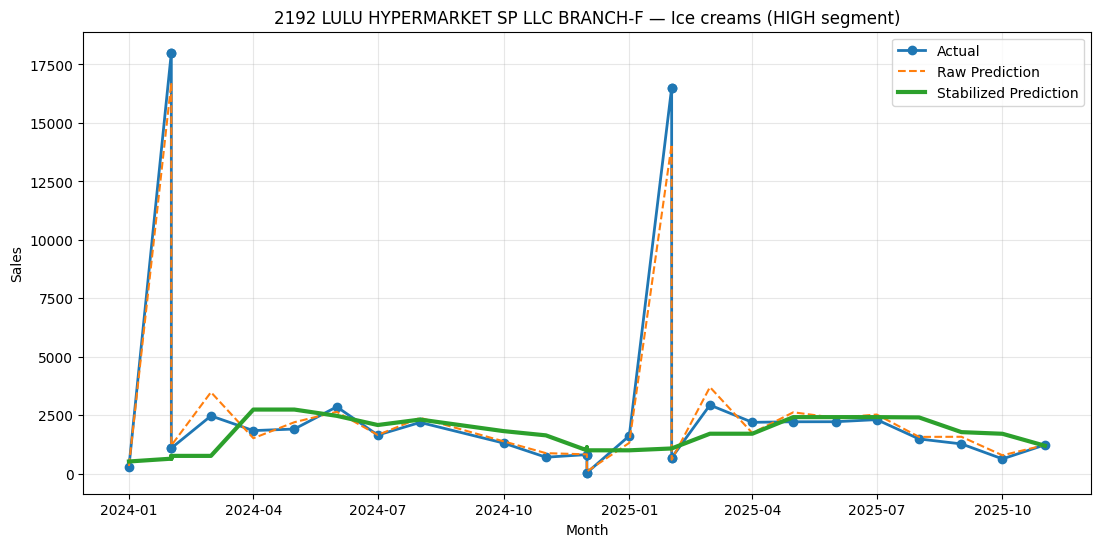

In [12]:
plt.figure(figsize=(13,6))

plt.plot(view["PLOT_DATE"], view["SALES"], 
         marker="o", label="Actual", linewidth=2)

plt.plot(view["PLOT_DATE"], view["PREDICTION"], 
         linestyle="--", label="Raw Prediction")

plt.plot(view["PLOT_DATE"], view["STABILIZED_FINAL"], 
         linewidth=3, label="Stabilized Prediction")

plt.title(f"{customer} — {product} ({SEG.upper()} segment)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [15]:
def metrics(a, p):
    return {
        "MAE": np.mean(np.abs(a - p)),
        "MAPE": np.mean(np.abs((a - p) / (a + 1e-6))) * 100
    }

a = view["SALES"].values
p_raw = view["PREDICTION"].values
p_stab = view["STABILIZED_FINAL"].values

print("RAW :", metrics(a, p_raw))
print("STAB:", metrics(a, p_stab))


RAW : {'MAE': 422.1048409049326, 'MAPE': 19.73212562926808}
STAB: {'MAE': 2611.201491994407, 'MAPE': 187.93443136531673}


In [14]:
for seg in segments:
    df = raw[seg].merge(
        stab[seg][[
            "CUSTOMER",
            "PRODUCT_GROUP",
            "PLOT_DATE",
            "STABILIZED_FINAL"
        ]],
        on=["CUSTOMER","PRODUCT_GROUP","PLOT_DATE"],
        how="left"
    )

    a = df["SALES"].values
    r = df["PREDICTION"].values
    s = df["STABILIZED_FINAL"].values

    print(f"\nSEGMENT: {seg.upper()}")
    print("  Raw  MAE:", np.mean(np.abs(a - r)))
    print("  Stab MAE:", np.mean(np.abs(a - s)))



SEGMENT: HIGH
  Raw  MAE: 489.664467709436
  Stab MAE: 1250.498231210364

SEGMENT: MEDIUM
  Raw  MAE: 19.73205807024344
  Stab MAE: 221.51511667267945

SEGMENT: LOW
  Raw  MAE: 40.32337269827712
  Stab MAE: 210.30371998278514
